# Notebook 7 – Outlier Analysis
## Objective
Identify unusual observations and decide how to handle them based on evidence. **Do not automatically remove every outlier.**

An **outlier** is an observation far from most values. Outliers may occur due to data-entry mistakes, measurement errors, natural variability, rare events, or genuine unusual cases.

**Types:** univariate (unusual in one variable), multivariate (unusual combination of variables), global (unusual overall), and contextual (unusual in a specific context).

## 1. Load libraries and dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
DATA_PATH = Path( r"C:\Users\ramki\sprint_4\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH.resolve()}. Put the CSV beside this notebook or update DATA_PATH.")
df = pd.read_csv(DATA_PATH)
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Select numerical columns

In [2]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
print(numeric_cols)
display(df[numeric_cols].describe().T)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


## 3. IQR Method
IQR = Q3 − Q1. A common rule flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. These are investigation flags, not proof of error.

In [3]:
def iqr_summary(series):
    x = pd.to_numeric(series, errors="coerce").dropna()
    if x.empty:
        return {}
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (x < lo) | (x > hi)
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "Lower fence": lo,
            "Upper fence": hi, "Outlier count": int(mask.sum()),
            "Outlier %": round(mask.mean()*100, 2)}
display(pd.DataFrame({c: iqr_summary(df[c]) for c in numeric_cols}).T.round(3))

,Q1,Q3,IQR,Lower fence,Upper fence,Outlier count,Outlier %
SeniorCitizen,0.00,0.000,0.000,0.000,0.000,1142.0,16.21
tenure,9.00,55.000,46.000,-60.000,124.000,0.0,0.00
MonthlyCharges,35.50,89.850,54.350,-46.025,171.375,0.0,0.00
TotalCharges,401.45,3794.738,3393.288,-4688.481,8884.669,0.0,0.00


## 4. Review values flagged by IQR

In [4]:
for col in numeric_cols:
    x = pd.to_numeric(df[col], errors="coerce")
    valid = x.dropna()
    if valid.empty: continue
    q1, q3 = valid.quantile([.25, .75])
    iqr = q3 - q1
    mask = (x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)
    print(f"{col}: {int(mask.sum())} flagged")
    display(df.loc[mask, [col]].head(10))

SeniorCitizen: 1142 flagged


,SeniorCitizen
20,1
30,1
31,1
34,1
50,1
52,1
53,1
54,1
55,1
57,1


tenure: 0 flagged


,tenure


MonthlyCharges: 0 flagged


,MonthlyCharges


TotalCharges: 0 flagged


,TotalCharges


## 5. Z-score Method
A z-score measures how many standard deviations a value is from its mean. A common screening threshold is |z| > 3. It can be less reliable for skewed data or when extreme values affect the mean and standard deviation.

In [5]:
rows = []
for col in numeric_cols:
    x = pd.to_numeric(df[col], errors="coerce")
    sd = x.std()
    z = (x - x.mean()) / sd if pd.notna(sd) and sd != 0 else pd.Series(np.nan, index=x.index)
    mask = z.abs() > 3
    rows.append({"Variable": col, "Flagged count": int(mask.sum()),
                 "Flagged %": round(mask.sum()/max(x.notna().sum(), 1)*100, 2)})
display(pd.DataFrame(rows).set_index("Variable"))

,Flagged count,Flagged %
Variable,,
SeniorCitizen,0,0.0
tenure,0,0.0
MonthlyCharges,0,0.0
TotalCharges,0,0.0


## 6. Box plots

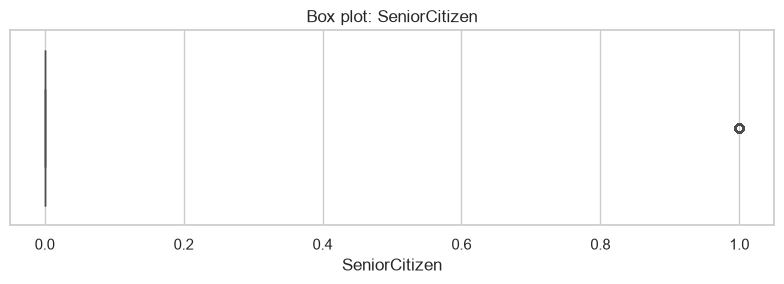

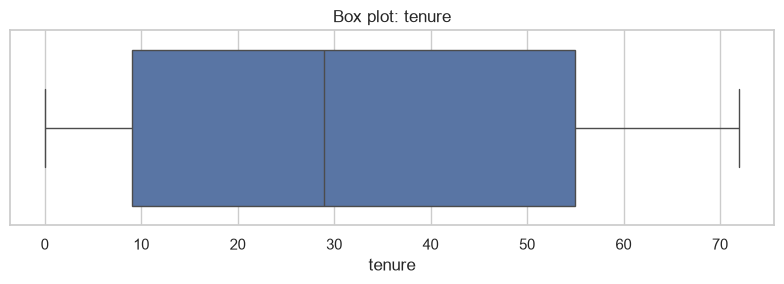

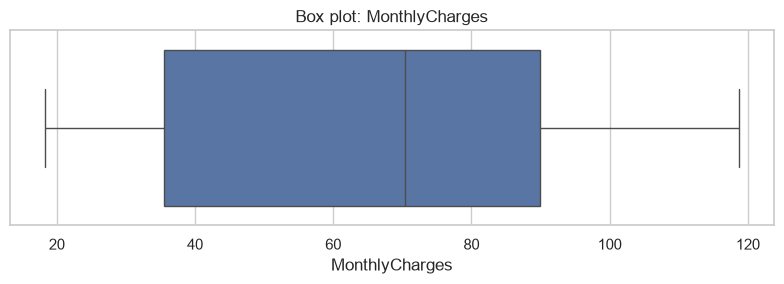

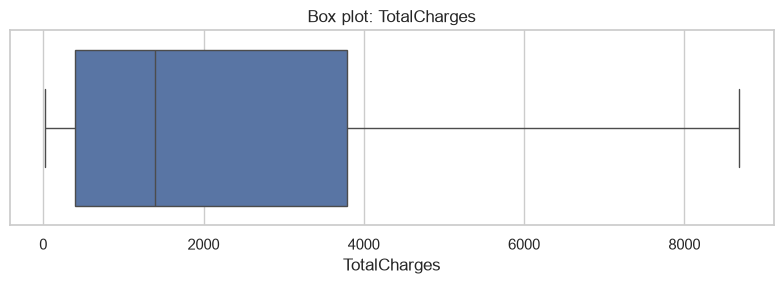

In [6]:
for col in numeric_cols:
    x = df[col].dropna()
    if x.empty: continue
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=x)
    plt.title(f"Box plot: {col}")
    plt.tight_layout()
    plt.show()

## 7. Scatter plots for unusual combinations

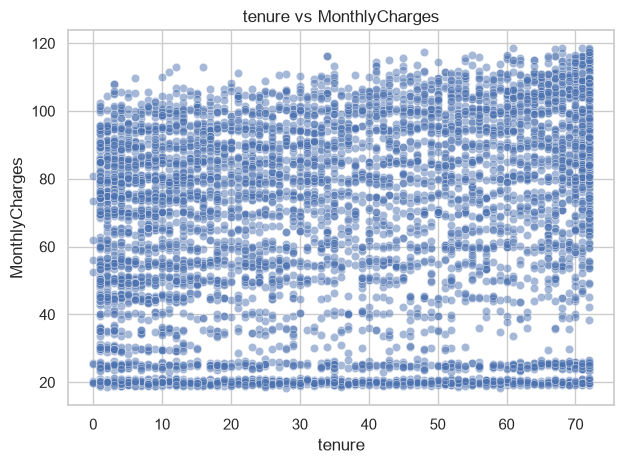

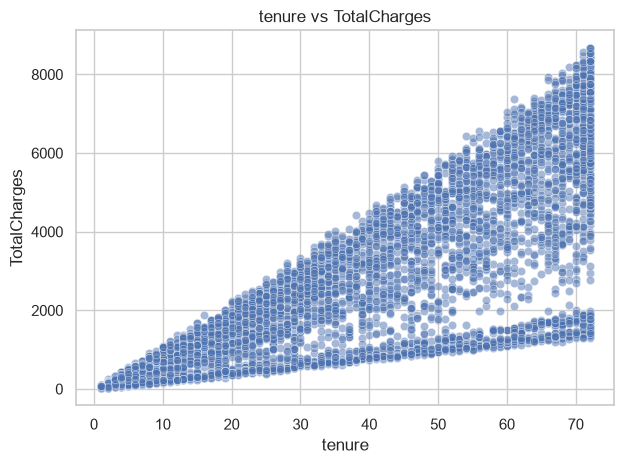

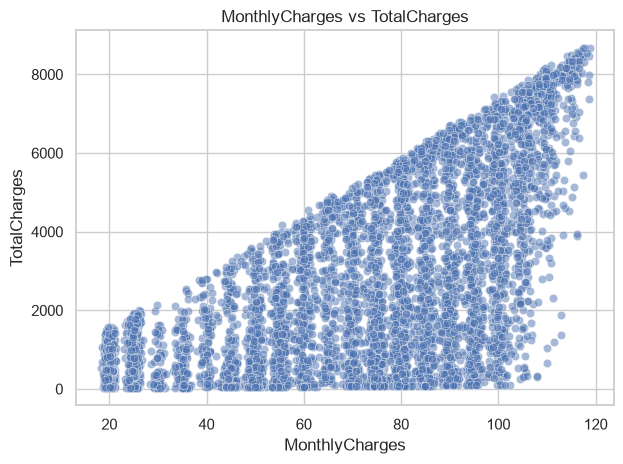

In [7]:
for xcol, ycol in [("tenure","MonthlyCharges"), ("tenure","TotalCharges"), ("MonthlyCharges","TotalCharges")]:
    if xcol in df.columns and ycol in df.columns:
        temp = df[[xcol, ycol]].dropna()
        sns.scatterplot(data=temp, x=xcol, y=ycol, alpha=.5)
        plt.title(f"{xcol} vs {ycol}")
        plt.tight_layout()
        plt.show()

## 8. Multivariate outlier screening
Isolation Forest screens for observations that are unusual across several numerical features. It is not proof that an observation is invalid. Requires scikit-learn (`pip install scikit-learn`) if not already installed.

In [8]:
try:
    from sklearn.ensemble import IsolationForest
    features = [c for c in numeric_cols if df[c].notna().any()]
    X = df[features].copy()
    X = X.fillna(X.median(numeric_only=True))
    if len(features) >= 2 and len(X) >= 10:
        labels = IsolationForest(contamination="auto", random_state=42).fit_predict(X)
        print(pd.Series(np.where(labels == -1, "Flagged", "Not flagged")).value_counts())
        display(df.loc[labels == -1].head(10))
    else:
        print("Not enough numerical features or rows.")
except ImportError:
    print("Install scikit-learn to run Isolation Forest: pip install scikit-learn")

Not flagged    4167
Flagged        2876
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No
14,5129-JLPIS,Male,0,No,No,25,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,105.50,2686.05,No
15,3655-SNQYZ,Female,0,Yes,Yes,69,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),113.25,7895.15,No
16,8191-XWSZG,Female,0,No,No,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.65,1022.95,No
17,9959-WOFKT,Male,0,No,Yes,71,Yes,Yes,Fiber optic,Yes,...,Yes,No,Yes,Yes,Two year,No,Bank transfer (automatic),106.70,7382.25,No
20,8779-QRDMV,Male,1,No,No,1,No,No phone service,DSL,No,...,Yes,No,No,Yes,Month-to-month,Yes,Electronic check,39.65,39.65,Yes
28,5248-YGIJN,Male,0,Yes,No,72,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),90.25,6369.45,No
30,3841-NFECX,Female,1,Yes,No,71,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,No,No,Two year,Yes,Credit card (automatic),96.35,6766.95,No


## 9. Decide how to handle outliers
For each flagged value, ask:
1. Is it a genuine observation?
2. Is it a data-entry or measurement error?
3. Is it unusual but valid?
4. Is removal justified by verified evidence?
5. Would a transformation be appropriate for the variable?
6. Should it be retained?

Document the evidence and reason for each decision. Valid extremes should usually be retained; correct confirmed errors where the source supports the correction.

In [9]:
review_template = pd.DataFrame(columns=[
    "Variable / row ID", "Flagged value", "Detection method",
    "Potential cause", "Verified error?", "Decision",
    "Reasoning / evidence"
])
display(review_template)

,Variable / row ID,Flagged value,Detection method,Potential cause,Verified error?,Decision,Reasoning / evidence


## 10. Findings and conclusion
Document which variables had the most flagged values, whether IQR and z-score agreed, what plots showed, whether any flagged values were verified errors, and why you retained, corrected, transformed, or removed them.

**Conclusion:** Outlier detection helps identify records for investigation; it does not automatically justify deletion.